# Bhili baseline LoRA fine-tuning (no vocabulary extension)

Baseline counterpart of the Bhili vocabulary-extension experiment. It uses the identical data, model, LoRA setup and training configuration, but the pretrained IndicTrans2 target vocabulary is left completely unchanged.

**Important language caveat:** `mar_Deva` is used as the same unverified target-language proxy as the existing Bhili baseline. It is not evidence that IndicTrans2 officially supports Bhili.


## Section 1. Environment

Install the pinned tokenizer/model toolkit versions once, restart the Kaggle session, then run verification. Do not start training until the decoder integrity checks pass.

In [1]:
# Section 1.1: install pinned dependencies (run ONCE, then restart the session)
%pip install -q --no-cache-dir \
    "transformers==4.46.3" \
    "tokenizers==0.20.3" \
    "IndicTransToolkit==1.1.1" \
    peft accelerate sacrebleu sentencepiece kagglehub

# Kaggle ships an old torchao that newer peft versions reject. This notebook does not use torchao.
%pip uninstall -y torchao

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
litellm 1.93.2 requires tokenizers<1.0,>=0.21.0, but you have tokenizers 0.20.3 which is incompatible.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.
Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Section 1.2: verify packages and GPU (run after the restart)
import sys
import importlib.metadata as metadata
import torch

print("=== Package versions ===")
for package in ["transformers", "tokenizers", "IndicTransToolkit", "torch", "peft", "accelerate", "sacrebleu", "sentencepiece", "torchao"]:
    try:
        print(f"{package:20s}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        print(f"{package:20s}: NOT INSTALLED")

print("\nPython:", sys.version.split()[0])
assert torch.cuda.is_available(), "No GPU. Set Accelerator to GPU T4 and restart the session."
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory (GiB): %.1f" % (torch.cuda.get_device_properties(0).total_memory / 1024**3))

import transformers
assert transformers.__version__ == "4.46.3", "transformers is not 4.46.3: rerun the install cell and restart the session."

=== Package versions ===
transformers        : 4.46.3
tokenizers          : 0.20.3
IndicTransToolkit   : 1.1.1
torch               : 2.11.0+cu128
peft                : 0.20.0
accelerate          : 1.14.0
sacrebleu           : 2.6.0
sentencepiece       : 0.2.2
torchao             : NOT INSTALLED

Python: 3.13.15
GPU: Tesla T4
GPU memory (GiB): 14.6


## Section 2. Authentication and run configuration

**Edit this section only when intentionally creating a different run.** This copy is the vocabulary-unchanged baseline with seed 42. Its training configuration is identical to the vocabulary-extended run (`bhili_extended_f05`). Section numbering is kept aligned with that notebook, so Section 5 (candidate words) is intentionally absent. This notebook starts its own clean run.

In [3]:
# Section 2.1: imports, Hugging Face login, and Bhili run configuration
import gc, glob, json, math, os, random, re, shutil, time, unicodedata, warnings, zipfile
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LambdaLR
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

warnings.filterwarnings("ignore")

hf_token = UserSecretsClient().get_secret("HF_TOKEN")
assert hf_token, "Add your Hugging Face access token to Kaggle Secrets as HF_TOKEN."
login(token=hf_token)
print("Hugging Face authentication complete.")

# ---------------- EDIT THESE ----------------
SEED = 42
# --------------------------------------------

DEVICE = torch.device("cuda")
MODEL_ID = "ai4bharat/indictrans2-indic-indic-1B"
SRC_LANG, TGT_LANG = "hin_Deva", "mar_Deva"  # target tag is an unverified Bhili proxy
SRC_COL, TGT_COL = "Hindi", "Bhili"

# Training configuration: identical to the vocabulary-extended run.
BATCH_SIZE, GRAD_ACCUM = 4, 4
NUM_EPOCHS = 10
LEARNING_RATE, WEIGHT_DECAY = 1e-4, 0.01
WARMUP_RATIO, MAX_GRAD_NORM = 0.03, 1.0
PATIENCE, MIN_DELTA = 2, 0.001
MAX_LEN = 256
MAX_EPOCHS_THIS_SESSION = NUM_EPOCHS  # lower to stop after N completed epochs, then resume later

RUN_NAME = f"bhili_baseline_s{SEED}"
RUN_DIR = Path("/kaggle/working") / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)
PRED_DIR = RUN_DIR / "predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

seed_everything(SEED)
print("Run:", RUN_NAME, "| output folder:", RUN_DIR)
print("Direction:", SRC_COL, "→", TGT_COL, "| target-tag caveat:", TGT_LANG)
with open(RUN_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump({"run_name": RUN_NAME, "model_id": MODEL_ID, "src_lang": SRC_LANG, "tgt_lang_proxy": TGT_LANG,
               "source_column": SRC_COL, "target_column": TGT_COL, "vocabulary_extension": False,
               "seed": SEED, "batch_size": BATCH_SIZE,
               "gradient_accumulation": GRAD_ACCUM, "epochs": NUM_EPOCHS, "learning_rate": LEARNING_RATE,
               "weight_decay": WEIGHT_DECAY, "max_length": MAX_LEN}, f, indent=2, ensure_ascii=False)

Hugging Face authentication complete.
Run: bhili_baseline_s42 | output folder: /kaggle/working/bhili_baseline_s42
Direction: Hindi → Bhili | target-tag caveat: mar_Deva


## Section 3. Data

Load the published Bhili Parquet splits used by the existing baseline. Validation selects checkpoints; test is held out for final evaluation.

In [4]:
# Section 3.1: locate and load the exact Bhili splits
INPUT_ROOT = Path("/kaggle/input")
print("Top-level input folders:")
for p in sorted(INPUT_ROOT.iterdir()):
    print(" -", p.name)

matches = [p for p in INPUT_ROOT.rglob("bhili_train.parquet") if p.parent.name == "splits"]
assert len(matches) == 1, (
    f"Expected one splits/bhili_train.parquet, found {len(matches)}. "
    "Attach the Common Tribal Languages Preprocessing dataset."
)
SPLIT_DIR = matches[0].parent
train_df = pd.read_parquet(SPLIT_DIR / "bhili_train.parquet").reset_index(drop=True)
val_df = pd.read_parquet(SPLIT_DIR / "bhili_validation.parquet").reset_index(drop=True)
test_df = pd.read_parquet(SPLIT_DIR / "bhili_test.parquet").reset_index(drop=True)

for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    assert {SRC_COL, TGT_COL} <= set(df.columns), f"{name}: missing {SRC_COL}/{TGT_COL}; found {df.columns.tolist()}"
    assert df[[SRC_COL, TGT_COL]].notna().all().all(), f"{name}: missing values"
    assert (df[SRC_COL].astype(str).str.strip() != "").all(), f"{name}: empty Hindi sentences"
    assert (df[TGT_COL].astype(str).str.strip() != "").all(), f"{name}: empty Bhili sentences"
    print(f"{name:11s}: {len(df):,} rows")

assert (len(train_df), len(val_df), len(test_df)) == (17817, 990, 990), "Split sizes differ from the existing Bhili experiment."
pair_sets = {name: set(df[[SRC_COL, TGT_COL]].itertuples(index=False, name=None))
             for name, df in [("train", train_df), ("validation", val_df), ("test", test_df)]}
for a,b in [("train","validation"),("train","test"),("validation","test")]:
    overlap = len(pair_sets[a] & pair_sets[b])
    print(f"Exact pair overlap {a}/{b}: {overlap}")
    assert overlap == 0, f"Exact pair overlap found between {a} and {b}."
print("Example Hindi:", train_df.iloc[0][SRC_COL])
print("Example Bhili:", train_df.iloc[0][TGT_COL])

Top-level input folders:
 - datasets
train      : 17,817 rows
validation : 990 rows
test       : 990 rows
Exact pair overlap train/validation: 0
Exact pair overlap train/test: 0
Exact pair overlap validation/test: 0
Example Hindi: इंफ्रास्ट्रक्चर और टेक्नोलॉजी निवेश में वृद्धि हो रही है।
Example Bhili: इन्‍फ्रास्‍ट्रक्‍चर मानकों नी रीतें एआई अनुसंधान अनें विकास करवा नों प्रोत्‍साहन मळिरों से।


## Section 4. Tokenizer and source preprocessor

Keep the pretrained IndicTrans2 tokenizer and model vocabulary unchanged. `mar_Deva` is a proxy tag inherited from the existing baseline; Bhili support is unverified.

In [5]:
# Section 4.1: tokenizer and IndicProcessor
from transformers import AutoTokenizer
from IndicTransToolkit import IndicProcessor

tok = AutoTokenizer.from_pretrained(MODEL_ID, trust_remote_code=True, token=hf_token)
processor = IndicProcessor(inference=True)
sp = tok.tgt_spm
BASE_TARGET_VOCAB_SIZE = len(tok.tgt_encoder)
EOS_ID, PAD_ID, DEC_START_ID, UNK_ID = 2, 1, 2, 3

print("Tokenizer:", type(tok).__name__, "| source vocab:", tok.src_vocab_size, "| target vocab:", tok.tgt_vocab_size)
assert (tok.src_vocab_size, tok.tgt_vocab_size) == (122706, 122672)
assert BASE_TARGET_VOCAB_SIZE == 122672
assert (tok.eos_token_id, tok.pad_token_id) == (EOS_ID, PAD_ID)
print("Tokenizer remains unchanged; target language tag remains an unverified proxy.")

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenization_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- tokenization_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


dict.SRC.json: 0.00B [00:00, ?B/s]

dict.TGT.json: 0.00B [00:00, ?B/s]

model.SRC:   0%|          | 0.00/3.26M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

Tokenizer: IndicTransTokenizer | source vocab: 122706 | target vocab: 122672
Tokenizer remains unchanged; target language tag remains an unverified proxy.


## Section 5. Candidate words

Not applicable: this baseline adds no vocabulary. The section is omitted so that numbering matches the vocabulary-extended notebook.

## Section 6. Target encoder and decoder

Targets are encoded with the original pretrained target tokenizer (special IDs removed; EOS is added once in the collator), exactly as the extended notebook encodes text containing no added words. Decoding uses the same `tok.decode` settings as the extended notebook. The integrity check in the next cell must pass before model training.

In [6]:
# Section 6.1: original target encoder and decoder
def encode_target(text, add_eos=False):
    if not isinstance(text, str):
        raise TypeError("Target text must be a string.")
    with tok.as_target_tokenizer():
        pieces = tok.tokenize(text) if text else []
        ids = tok.convert_tokens_to_ids(pieces)
    blocked_ids = {EOS_ID, PAD_ID, DEC_START_ID}
    ids = [int(t) for t in ids if int(t) not in blocked_ids]
    if add_eos and (not ids or ids[-1] != EOS_ID):
        ids.append(EOS_ID)
    return ids

def decode_generated(token_ids):
    if isinstance(token_ids, torch.Tensor):
        token_ids = token_ids.detach().cpu().tolist()
    ids = [int(x) for x in token_ids]
    if ids and ids[0] == DEC_START_ID:
        ids = ids[1:]
    clean = []
    for token_id in ids:
        if token_id == EOS_ID:
            break
        if token_id == PAD_ID:
            continue
        clean.append(token_id)
    return tok.decode(clean, skip_special_tokens=True, clean_up_tokenization_spaces=True).strip()

print("Original target encoder and decoder defined.")


Original target encoder and decoder defined.


In [7]:
# Section 6.2: encoder/decoder integrity checks
val_texts = val_df[TGT_COL].astype(str).str.strip().tolist()
test_texts_ref = test_df[TGT_COL].astype(str).str.strip().tolist()

checked = mismatch = unk_ids = total_ids = 0
for text in val_texts[:300] + test_texts_ref[:300]:
    ids = encode_target(text)
    assert all(0 <= t < BASE_TARGET_VOCAB_SIZE for t in ids), "Encoded ID outside the original vocabulary."
    direct = tok.decode(ids, skip_special_tokens=True, clean_up_tokenization_spaces=True).strip()
    mismatch += int(decode_generated([DEC_START_ID] + ids + [EOS_ID]) != direct)
    unk_ids += sum(t == UNK_ID for t in ids); total_ids += len(ids)
    checked += 1
print(f"Decoder consistency: {checked} sentences, {mismatch} mismatches (must be 0)")
print(f"UNK rate in encoded targets: {unk_ids}/{total_ids}")
assert mismatch == 0, "Decoder is inconsistent with tok.decode."
print("PASS: encoder/decoder integrity check.")


Decoder consistency: 600 sentences, 0 mismatches (must be 0)
UNK rate in encoded targets: 9/19416
PASS: encoder/decoder integrity check.


## Section 7. Training examples, collator and loaders
Sources are preprocessed with `IndicProcessor` (as in all earlier runs). Labels use the original target encoder with EOS appended once, truncated to 256 with EOS kept, padding masked as -100. The training loader uses a generator seeded with `SEED + epoch`, so the data order is reproducible and survives a resume.

In [8]:
# Section 7.1: examples (preprocessing ~18k sources takes a minute or two)
def prepare_examples(df):
    out = []
    for _, row in df.iterrows():
        s, t = str(row[SRC_COL]).strip(), str(row[TGT_COL]).strip()
        if not s or not t:
            continue
        out.append({"source": processor.preprocess_batch([s], src_lang=SRC_LANG, tgt_lang=TGT_LANG)[0], "target": t})
    return out

train_examples = prepare_examples(train_df)
val_examples = prepare_examples(val_df)
print("Train / validation examples:", len(train_examples), len(val_examples), "(expected 17817 / 990)")
assert (len(train_examples), len(val_examples)) == (17817, 990)

Train / validation examples: 17817 990 (expected 17817 / 990)


In [9]:
# Section 7.2: dataset, collator, and data loaders
class ListDataset(Dataset):
    def __init__(self, examples): self.examples = examples
    def __len__(self): return len(self.examples)
    def __getitem__(self, i): return self.examples[i]

def collate(examples):
    src = tok([e["source"] for e in examples], padding=True, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    seqs = []
    for e in examples:
        ids = encode_target(e["target"], add_eos=True)[:MAX_LEN]
        if not ids:
            ids = [EOS_ID]
        if ids[-1] != EOS_ID:
            ids = ids[:-1] + [EOS_ID]
        seqs.append(ids)
    longest = max(len(x) for x in seqs)
    labels = torch.full((len(seqs), longest), -100, dtype=torch.long)
    for i, ids in enumerate(seqs):
        labels[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)
    return {"input_ids": src["input_ids"], "attention_mask": src["attention_mask"], "labels": labels}

train_dataset, val_dataset = ListDataset(train_examples), ListDataset(val_examples)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate)
def make_train_loader(epoch):
    g = torch.Generator(); g.manual_seed(SEED + epoch)
    return DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=g, collate_fn=collate)

n_batches = len(make_train_loader(1))
steps_per_epoch = math.ceil(n_batches / GRAD_ACCUM)
total_steps = steps_per_epoch * NUM_EPOCHS
warmup_steps = int(total_steps * WARMUP_RATIO)
print("Batches/epoch:", n_batches, "| optimizer steps/epoch:", steps_per_epoch,
      "| planned optimizer steps:", total_steps, "| warmup:", warmup_steps)

batch = next(iter(make_train_loader(1)))
valid = batch["labels"][batch["labels"] != -100]
for row in batch["labels"]:
    row_valid = row[row != -100]
    assert len(row_valid) > 0 and row_valid[-1].item() == EOS_ID
assert int(valid.max()) < BASE_TARGET_VOCAB_SIZE and int(valid.min()) >= 0
print("Batch shapes:", {k: tuple(v.shape) for k, v in batch.items()})
print("PASS: labels end in EOS and IDs stay within the original vocabulary.")

Batches/epoch: 4455 | optimizer steps/epoch: 1114 | planned optimizer steps: 11140 | warmup: 334
Batch shapes: {'input_ids': (4, 34), 'attention_mask': (4, 34), 'labels': (4, 40)}
PASS: labels end in EOS and IDs stay within the original vocabulary.


## Section 8. Model and LoRA

The pretrained model is loaded in fp16 and frozen; the decoder embedding and output layer are unchanged. LoRA adapters (same configuration as the extended run) are the only trainable parameters, stored in fp32.

In [10]:
# Section 8.1: base model and LoRA
from transformers import AutoModelForSeq2SeqLM
from peft import LoraConfig, get_peft_model, TaskType

for name in ["model", "lora_model"]:
    if name in globals():
        del globals()[name]
gc.collect(); torch.cuda.empty_cache()

seed_everything(SEED)
model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_ID, trust_remote_code=True, token=hf_token, torch_dtype=torch.float16, low_cpu_mem_usage=True,
).to(DEVICE)

lora_cfg = LoraConfig(r=16, lora_alpha=32, target_modules=["q_proj", "v_proj"],
                      lora_dropout=0.05, bias="none", task_type=TaskType.SEQ_2_SEQ_LM)
lora_model = get_peft_model(model, lora_cfg)
print("LoRA attached. Decoder vocabulary unchanged:", BASE_TARGET_VOCAB_SIZE)

config.json: 0.00B [00:00, ?B/s]

configuration_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- configuration_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


modeling_indictrans.py: 0.00B [00:00, ?B/s]

A new version of the following files was downloaded from https://huggingface.co/ai4bharat/indictrans2-indic-indic-1B:
- modeling_indictrans.py
. Make sure to double-check they do not contain any added malicious code. To avoid downloading new versions of the code file, you can pin a revision.


model.safetensors:   0%|          | 0.00/4.83G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/168 [00:00<?, ?B/s]

LoRA attached. Decoder vocabulary unchanged: 122672


In [11]:
# Section 8.2: trainable parameters (LoRA only)
trainable_params = [p for p in lora_model.parameters() if p.requires_grad]
for p in trainable_params:
    if p.dtype != torch.float32:
        p.data = p.data.float()
n_lora = 3_538_944
n_train = sum(p.numel() for p in trainable_params)
print("Trainable parameters:", f"{n_train:,}", "| LoRA:", f"{n_lora:,}")
assert n_train == n_lora, "Unexpected trainable parameter count."
print("Trainable dtypes:", {str(p.dtype) for p in trainable_params})
inner = lora_model.base_model.model
print("Output layer size:", inner.lm_head.weight.shape[0], "| expected", BASE_TARGET_VOCAB_SIZE)
assert inner.lm_head.weight.shape[0] == BASE_TARGET_VOCAB_SIZE


Trainable parameters: 3,538,944 | LoRA: 3,538,944
Trainable dtypes: {'torch.float32'}
Output layer size: 122672 | expected 122672


In [12]:
# Section 8.3: optimizer, scheduler, scaler, training state
optimizer = torch.optim.AdamW(trainable_params, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

def lr_lambda(step):
    if step < warmup_steps:
        return max(step, 1) / max(warmup_steps, 1)
    return max(0.0, 1.0 - (step - warmup_steps) / max(total_steps - warmup_steps, 1))

scheduler = LambdaLR(optimizer, lr_lambda=lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=True)
S = dict(next_epoch=1, best_val=float("inf"), no_improve=0, history=[], global_step=0, skipped=0)
print("Optimizer: AdamW | lr", LEARNING_RATE, "| weight decay", WEIGHT_DECAY, "| scaler scale:", scaler.get_scale())

Optimizer: AdamW | lr 0.0001 | weight decay 0.01 | scaler scale: 65536.0


## Section 9. Validation function and resumable checkpoints
A full checkpoint (all trainable weights, optimizer, scheduler, scaler, history, early-stopping state, RNG states) is written after every epoch. If a backup from an earlier session of the same run is attached as a dataset (folder named like the run), training resumes from it automatically. A step-0 validation loss is also printed as a sanity check.

In [13]:
# Section 9.1: validation and checkpoint functions
@torch.no_grad()
def evaluate_validation():
    lora_model.eval()
    losses = []
    for vb in val_loader:
        vb = {k: v.to(DEVICE) for k, v in vb.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            out = lora_model(**vb, use_cache=False, return_dict=True)
        losses.append(out.loss.float().item())
    return float(np.mean(losses))

def trainable_state():
    return {n: p.detach().cpu() for n, p in lora_model.named_parameters() if p.requires_grad}

def save_state(path):
    state = {"trainable": trainable_state(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
             "scaler": scaler.state_dict(), "S": dict(S), "run": {"SEED": SEED},
             "rng": {"py": random.getstate(), "np": np.random.get_state(),
                     "torch": torch.get_rng_state(), "cuda": torch.cuda.get_rng_state_all()}}
    tmp = str(path) + ".tmp"
    torch.save(state, tmp); os.replace(tmp, path)

def load_trainable(state_dict):
    params = dict(lora_model.named_parameters())
    for n, v in state_dict.items():
        params[n].data.copy_(v.to(params[n].device, params[n].dtype))

def load_state(path):
    st = torch.load(path, map_location="cpu", weights_only=False)
    assert st["run"] == {"SEED": SEED}, f"Checkpoint is from a different configuration: {st['run']}"
    load_trainable(st["trainable"])
    optimizer.load_state_dict(st["optimizer"]); scheduler.load_state_dict(st["scheduler"])
    scaler.load_state_dict(st["scaler"]); S.update(st["S"])
    random.setstate(st["rng"]["py"]); np.random.set_state(st["rng"]["np"])
    torch.set_rng_state(st["rng"]["torch"]); torch.cuda.set_rng_state_all(st["rng"]["cuda"])
    print(f"Resumed. Next epoch: {S['next_epoch']} | best validation loss: {S['best_val']:.4f} | epochs recorded: {len(S['history'])}")

local = RUN_DIR / "latest.pt"
attached = glob.glob(f"/kaggle/input/**/{RUN_NAME}/latest.pt", recursive=True)
if local.exists():
    load_state(local)
elif attached:
    src_dir = Path(attached[0]).parent
    load_state(attached[0])
    for item in ["best_trainable.pt", "training_history.json"]:
        s = src_dir / item
        if s.exists():
            shutil.copy(s, RUN_DIR / item)
    print("Copied best weights and history from the attached checkpoint.")
else:
    print("No checkpoint found: starting a fresh run.")
    t0 = time.time()
    v0 = evaluate_validation()
    print(f"Step-0 validation loss of the untuned model: {v0:.4f} ({time.time()-t0:.0f} s). "
          "Must be finite; a huge value signals a label problem.")
    assert np.isfinite(v0)

No checkpoint found: starting a fresh run.
Step-0 validation loss of the untuned model: 8.7260 (20 s). Must be finite; a huge value signals a label problem.


## Section 10. Training

The training loop is resumable from the latest completed epoch. It uses FP16 autocast, FP32 master parameters for the new rows and LoRA weights, finite-gradient checks, clipping at a global norm of 1.0, and validation-loss-based early stopping. If a loss becomes non-finite, stop and inspect the last completed checkpoint rather than continuing with corrupted weights.

In [14]:
# Section 10.1: training loop (resumable)
done_this_session, stopped_early = 0, False
for epoch in range(S["next_epoch"], NUM_EPOCHS + 1):
    if done_this_session >= MAX_EPOCHS_THIS_SESSION:
        print("Session epoch limit reached. Resume from the saved checkpoint in a later session.")
        break

    train_loader = make_train_loader(epoch)
    lora_model.train()
    optimizer.zero_grad(set_to_none=True)
    running, nb, epoch_skipped, gnorms, t0 = 0.0, 0, 0, [], time.time()

    for b_idx, batch in enumerate(train_loader, start=1):
        batch = {k: v.to(DEVICE) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            loss = lora_model(**batch, use_cache=False, return_dict=True).loss
        if not torch.isfinite(loss).item():
            optimizer.zero_grad(set_to_none=True)
            raise RuntimeError(f"Non-finite loss at epoch {epoch}, batch {b_idx}. The checkpoint from the last completed epoch is intact.")

        group_start = ((b_idx - 1) // GRAD_ACCUM) * GRAD_ACCUM
        group_size = min(GRAD_ACCUM, n_batches - group_start)
        scaler.scale(loss / group_size).backward()
        running += loss.detach().float().item(); nb += 1

        if b_idx % GRAD_ACCUM == 0 or b_idx == n_batches:
            scaler.unscale_(optimizer)
            finite, sq = True, torch.zeros((), device=DEVICE, dtype=torch.float64)
            for p in trainable_params:
                if p.grad is None:
                    continue
                g = p.grad.detach()
                if not torch.isfinite(g).all().item():
                    finite = False
                    break
                sq += g.to(torch.float64).square().sum()
            old_scale = scaler.get_scale()
            if finite:
                gn = sq.sqrt().item(); gnorms.append(gn)
                coef = min(1.0, MAX_GRAD_NORM / (gn + 1e-12))
                if coef < 1.0:
                    for p in trainable_params:
                        if p.grad is not None:
                            p.grad.mul_(coef)
            scaler.step(optimizer); scaler.update()
            if (not finite) or scaler.get_scale() < old_scale:
                epoch_skipped += 1
            optimizer.zero_grad(set_to_none=True)
            scheduler.step(); S["global_step"] += 1

        if b_idx % 500 == 0:
            print(f"Epoch {epoch}/{NUM_EPOCHS} | batch {b_idx}/{n_batches} | avg loss {running/nb:.4f} | "
                  f"lr {optimizer.param_groups[0]['lr']:.2e} | scale {scaler.get_scale():.0f} | skipped {epoch_skipped} | {(time.time()-t0)/60:.1f} min")

    train_loss = running / nb
    val_loss = evaluate_validation()
    improved = val_loss < S["best_val"] - MIN_DELTA
    if improved:
        S["best_val"], S["no_improve"] = val_loss, 0
        torch.save(trainable_state(), RUN_DIR / "best_trainable.pt")
    else:
        S["no_improve"] += 1
    S["skipped"] += epoch_skipped
    S["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "best_val_loss": S["best_val"],
                         "improved": improved, "lr": optimizer.param_groups[0]["lr"], "global_step": S["global_step"],
                         "skipped_updates": epoch_skipped,
                         "grad_norm_mean": float(np.mean(gnorms)) if gnorms else None,
                         "grad_norm_max": float(np.max(gnorms)) if gnorms else None,
                         "minutes": (time.time() - t0) / 60})
    S["next_epoch"] = epoch + 1
    save_state(RUN_DIR / "latest.pt")
    json.dump(S["history"], open(RUN_DIR / "training_history.json", "w"), indent=2)
    print(f"\n=== Epoch {epoch}/{NUM_EPOCHS} complete | train {train_loss:.4f} | val {val_loss:.4f} | best {S['best_val']:.4f} | "
          f"skipped updates {epoch_skipped} | {(time.time()-t0)/60:.1f} min | patience {S['no_improve']}/{PATIENCE} ===\n")
    done_this_session += 1
    if S["no_improve"] >= PATIENCE:
        print("Early stopping triggered.")
        stopped_early = True
        break

print("Epochs completed:", len(S["history"]), "| total skipped updates:", S["skipped"], "| stopped early:", stopped_early)

Epoch 1/10 | batch 500/4455 | avg loss 8.2005 | lr 3.74e-05 | scale 65536 | skipped 0 | 1.6 min
Epoch 1/10 | batch 1000/4455 | avg loss 7.2464 | lr 7.49e-05 | scale 65536 | skipped 0 | 3.1 min
Epoch 1/10 | batch 1500/4455 | avg loss 6.6414 | lr 9.96e-05 | scale 65536 | skipped 0 | 4.7 min
Epoch 1/10 | batch 2000/4455 | avg loss 6.2756 | lr 9.85e-05 | scale 65536 | skipped 0 | 6.2 min
Epoch 1/10 | batch 2500/4455 | avg loss 6.0064 | lr 9.73e-05 | scale 65536 | skipped 0 | 7.8 min
Epoch 1/10 | batch 3000/4455 | avg loss 5.8129 | lr 9.62e-05 | scale 65536 | skipped 0 | 9.3 min
Epoch 1/10 | batch 3500/4455 | avg loss 5.6671 | lr 9.50e-05 | scale 65536 | skipped 0 | 10.9 min
Epoch 1/10 | batch 4000/4455 | avg loss 5.5465 | lr 9.38e-05 | scale 65536 | skipped 0 | 12.4 min

=== Epoch 1/10 complete | train 5.4557 | val 4.5063 | best 4.5063 | skipped updates 0 | 14.1 min | patience 0/2 ===

Epoch 2/10 | batch 500/4455 | avg loss 4.6302 | lr 9.16e-05 | scale 65536 | skipped 0 | 1.6 min
Epoch 2/1

## Section 11. Training summary and backup

Inspect the recorded training history and make a recovery backup before the session ends. The backup contains optimizer and scheduler state for resuming; the smaller final results bundle is created later and excludes duplicate recovery checkpoints.

,epoch,train_loss,val_loss,best_val_loss,improved,lr,global_step,skipped_updates,grad_norm_mean,grad_norm_max,minutes
0,1,5.4557,4.5063,4.5063,True,0.0001,1114,0,1.1341,2.1672,14.1414
1,2,4.5306,4.2837,4.2837,True,0.0001,2228,0,1.4965,2.5155,14.1369
2,3,4.3609,4.1505,4.1505,True,0.0001,3342,0,1.6074,3.8139,14.1192
3,4,4.2516,4.0782,4.0782,True,0.0001,4456,1,1.6646,2.8105,14.0957
4,5,4.1796,4.0172,4.0172,True,0.0001,5570,0,1.7144,3.7321,14.0354
5,6,4.1164,3.9777,3.9777,True,0.0000,6684,1,1.7518,4.0761,13.9678
6,7,4.0836,3.9539,3.9539,True,0.0000,7798,1,1.7834,3.1376,14.0508
7,8,4.0526,3.9409,3.9409,True,0.0000,8912,0,1.8083,3.5234,14.0351
8,9,4.0292,3.9310,3.9310,True,0.0000,10026,0,1.8279,3.5353,14.0196
9,10,4.0143,3.9231,3.9231,True,0.0000,11140,0,1.8439,3.2875,13.9535


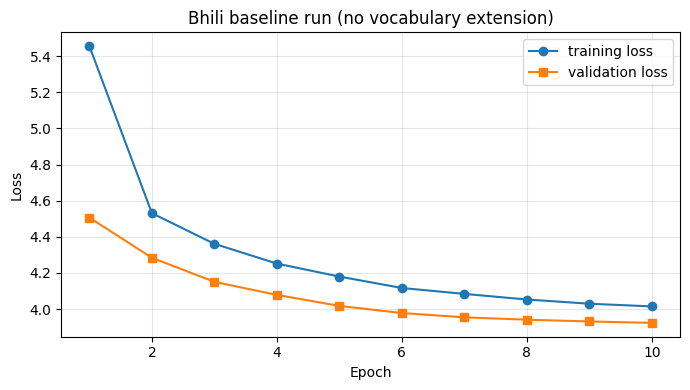

Total skipped gradient updates: 3


In [15]:
# Section 11.1: training history table and validation-loss plot
import matplotlib.pyplot as plt
hist_df = pd.DataFrame(S["history"])
if len(hist_df):
    display(hist_df.round(4))
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(hist_df["epoch"], hist_df["train_loss"], marker="o", label="training loss")
    ax.plot(hist_df["epoch"], hist_df["val_loss"], marker="s", label="validation loss")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_title("Bhili baseline run (no vocabulary extension)")
    ax.grid(alpha=0.3); ax.legend(); fig.tight_layout()
    fig.savefig(RUN_DIR / "training_loss.png", dpi=150); plt.show()
else:
    print("No completed epochs recorded yet; run the training cell first.")
print("Total skipped gradient updates:", S.get("skipped", 0))

In [16]:
# Section 11.2: backup (download this zip; it allows resuming or evaluating in a later session)
shutil.make_archive(f"/kaggle/working/{RUN_NAME}_backup", "zip", RUN_DIR.parent, RUN_NAME)
print(f"Backup written: /kaggle/working/{RUN_NAME}_backup.zip (%.1f MB)" % (os.path.getsize(f"/kaggle/working/{RUN_NAME}_backup.zip") / 1e6))

Backup written: /kaggle/working/bhili_baseline_s42_backup.zip (52.4 MB)


## Section 12. Evaluation under the baseline-matched pipeline

Use `IndicProcessor` prompts, batch size 8, **5 beams**, `max_new_tokens=256`, and no sampling to match the saved Bhili baseline inference settings. Generate predictions for the first 300 validation examples and all 990 test examples. Run the decoder integrity checks before reaching this section.

In [17]:
# Section 12.1: load best weights and define generation (baseline-matched settings)
best_path = RUN_DIR / "best_trainable.pt"
assert best_path.exists(), "No best_trainable.pt found: complete training first."
load_trainable(torch.load(best_path, map_location="cpu", weights_only=False))
lora_model.eval()
print("Loaded best trainable weights (validation loss %.4f)." % S["best_val"])

@torch.inference_mode()
def translate(sources, batch_size=8):
    prompts = [processor.preprocess_batch([s], src_lang=SRC_LANG, tgt_lang=TGT_LANG)[0] for s in sources]
    texts, id_lists = [], []
    for i in range(0, len(prompts), batch_size):
        enc = tok(prompts[i:i + batch_size], padding=True, truncation=True,
                  max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
        gen = lora_model.generate(**enc, max_new_tokens=256, num_beams=5, do_sample=False)
        for row in gen.cpu().tolist():
            id_lists.append(row)
            texts.append(decode_generated(row))
    texts = processor.postprocess_batch(texts, lang=TGT_LANG)
    return texts, id_lists

val_src = val_df[SRC_COL].astype(str).str.strip().tolist()[:300]
val_ref = val_df[TGT_COL].astype(str).str.strip().tolist()[:300]
test_src = test_df[SRC_COL].astype(str).str.strip().tolist()
test_ref = test_df[TGT_COL].astype(str).str.strip().tolist()

torch.cuda.empty_cache()
for source, reference, hypothesis in zip(val_src[:2], val_ref[:2], translate(val_src[:2])[0]):
    print("SRC:", source[:100]); print("REF:", reference[:100]); print("HYP:", hypothesis[:100]); print()

Loaded best trainable weights (validation loss 3.9231).
SRC: दूसरे शब्दों में, समानता प्रत्येक व्यक्ति के माध्यम से प्राप्त की जाती है जो अपनी क्षमता के अनुसार ख
REF: बिजा ब्रोह शब्‍दों मा समानता एक व्‍यक्ति ना वचमाना से की आपडी ताकत अनुसार खर्चा करे।
HYP: बीजा शब्दों मा समानता प्रत्येक व्यक्ति ना माध्यम थी प्राप्त करी जाय से जो आपडी क्षमता ना अनुसार खर्च

SRC: हमें इन मुद्दों पर साथ मिलकर काम करने के लिए शंघाई सहयोग संगठन भी एक महत्वपूर्ण ढांचा मुहैया कराएगा।
REF: हमु ने इना मुदा उपर हाते मलीने काम करवा हारू शंघाई सहयोग पार्टी पण एक खास ढ़ाचा आलवानों से ।
HYP: हमुने इना मुद्दा पर हाते हामे काम करवा हारू शंघाई सहयोग संगठन पण एक महत्वपूर्ण ढांचा प्रदान करहे।



In [18]:
# Section 12.2: generate validation (300 examples) and test (990 examples) predictions
preds, gen_ids = {}, {}
for split, sources, references in [("val300", val_src, val_ref), ("test", test_src, test_ref)]:
    t0 = time.time()
    hypotheses, ids = translate(sources)
    preds[split], gen_ids[split] = hypotheses, ids
    pd.DataFrame({"source": sources, "reference": references, "prediction": hypotheses}).to_csv(
        PRED_DIR / f"{RUN_NAME}_{split}.csv", index=False, encoding="utf-8-sig"
    )
    with open(PRED_DIR / f"{RUN_NAME}_{split}_generated_ids.json", "w", encoding="utf-8") as f:
        json.dump(ids, f)
    print(f"{split:7s} done in {(time.time() - t0) / 60:.1f} min")
print("Generated predictions for", len(preds["test"]), "held-out test examples.")

val300  done in 1.4 min
test    done in 4.1 min
Generated predictions for 990 held-out test examples.


## Section 13. Scoring and comparison with the saved Bhili baseline

Reports BLEU, chrF and TER on the held-out test set. If the previously saved baseline predictions are attached, the retrained baseline is also compared with them (paired-bootstrap intervals over test examples, 1,000 resamples) as a reproduction check. Bootstrap intervals capture test-example resampling uncertainty, not variation across independent training runs. The target language tag is still an unverified proxy for Bhili.

In [19]:
# Section 13.1: metric helpers
import sacrebleu

def _has(pattern, text): return re.search(pattern, text) is not None

def summarize(system, split, hyp, ref):
    b = sacrebleu.corpus_bleu(hyp, [ref]); c = sacrebleu.corpus_chrf(hyp, [ref]); t = sacrebleu.corpus_ter(hyp, [ref])
    return {"system": system, "split": split, "n": len(ref), "BLEU": round(b.score, 2), "chrF": round(c.score, 2),
            "TER": round(t.score, 2),
            "word_len_ratio": round(sum(len(h.split()) for h in hyp) / sum(len(r.split()) for r in ref), 3),
            "empty": sum(h == "" for h in hyp)}

def paired_bootstrap(hyp_a, hyp_b, ref, B=1000, seed=0):
    rng = np.random.default_rng(seed); n = len(ref); d_bleu, d_chrf = [], []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        r = [ref[i] for i in idx]; a = [hyp_a[i] for i in idx]; b = [hyp_b[i] for i in idx]
        d_bleu.append(sacrebleu.corpus_bleu(b, [r]).score - sacrebleu.corpus_bleu(a, [r]).score)
        d_chrf.append(sacrebleu.corpus_chrf(b, [r]).score - sacrebleu.corpus_chrf(a, [r]).score)
    return d_bleu, d_chrf

def show_bootstrap(label, hyp_a, hyp_b, ref, B=1000):
    d_bleu, d_chrf = paired_bootstrap(hyp_a, hyp_b, ref, B=B)
    out = {}
    for name, d in [("BLEU", d_bleu), ("chrF", d_chrf)]:
        lo, hi = np.percentile(d, [2.5, 97.5])
        out[name] = (float(np.mean(d)), float(lo), float(hi))
        print(f"{label} | {name}: mean {np.mean(d):+.2f}, 95% interval [{lo:+.2f}, {hi:+.2f}], B better in {100*np.mean(np.array(d) > 0):.1f}% of resamples")
    return out

def locate_file(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"/kaggle/working/**/{name}", recursive=True)
    return hits[0] if hits else None
print("Helpers ready.")

Helpers ready.


In [20]:
# Section 13.2: load the saved Bhili baseline test predictions
# The baseline notebook saves evaluation/baseline_test_predictions.csv with columns
# Hindi, Reference_Bhili, Predicted_Bhili. It may be attached as a directory or ZIP.
def load_bhili_baseline_predictions(expected_references):
    direct_hits = []
    for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
        if root.exists():
            direct_hits.extend(root.rglob("baseline_test_predictions.csv"))
    if direct_hits:
        frame = pd.read_csv(direct_hits[0], encoding="utf-8-sig")
        print("Loaded baseline predictions:", direct_hits[0])
    else:
        zip_hits = []
        for root in [Path("/kaggle/working"), Path("/kaggle/input")]:
            if root.exists():
                zip_hits.extend(root.rglob("bhili_baseline_artifacts.zip"))
        frame = None
        for zip_path in zip_hits:
            with zipfile.ZipFile(zip_path, "r") as zf:
                members = [n for n in zf.namelist() if n.endswith("baseline_test_predictions.csv")]
                if members:
                    with zf.open(members[0]) as handle:
                        frame = pd.read_csv(handle, encoding="utf-8-sig")
                    print("Loaded baseline predictions from:", zip_path, "member:", members[0])
                    break
        if frame is None:
            print("WARNING: baseline_test_predictions.csv was not found. Attach the baseline artifacts dataset/ZIP for comparative analysis.")
            return None

    needed = {"Reference_Bhili", "Predicted_Bhili"}
    assert needed.issubset(frame.columns), f"Unexpected baseline prediction columns: {frame.columns.tolist()}"
    baseline_references = frame["Reference_Bhili"].fillna("").astype(str).str.strip().tolist()
    baseline_hypotheses = frame["Predicted_Bhili"].fillna("").astype(str).str.strip().tolist()
    assert baseline_references == expected_references, "Baseline references/order differ from this notebook's held-out test split."
    assert len(baseline_hypotheses) == len(expected_references)
    return baseline_hypotheses

base_test = load_bhili_baseline_predictions(test_ref)
base_val = None  # existing baseline artifact contains test predictions, not validation predictions
print("Baseline test predictions available:", base_test is not None)

Baseline test predictions available: False


In [21]:
# Section 13.3: metrics and paired bootstrap
this_name = f"Bhili baseline LoRA, retrained here (seed {SEED})"
rows = []
if base_test is not None:
    rows.append(summarize("Bhili baseline LoRA (saved)", "test", base_test, test_ref))
rows.append(summarize(this_name, "test", preds["test"], test_ref))
score_table = pd.DataFrame(rows)
display(score_table)
score_table.to_csv(RUN_DIR / "scores.csv", index=False)

bleu_metric = sacrebleu.metrics.BLEU()
chrf_metric = sacrebleu.metrics.CHRF()
this_bleu = bleu_metric.corpus_score(preds["test"], [test_ref]).score
this_chrf = chrf_metric.corpus_score(preds["test"], [test_ref]).score
summary = {"run": RUN_NAME, "SEED": SEED,
           "best_val_loss": S["best_val"], "completed_epochs": len(S["history"]),
           "test_BLEU": float(this_bleu), "test_chrF": float(this_chrf),
           "BLEU_signature": str(bleu_metric.get_signature()), "chrF_signature": str(chrf_metric.get_signature())}
if base_test is not None:
    base_bleu = sacrebleu.corpus_bleu(base_test, [test_ref]).score
    base_chrf = sacrebleu.corpus_chrf(base_test, [test_ref]).score
    print("\nPaired bootstrap on test examples (retrained baseline minus saved baseline):")
    bs = show_bootstrap("Retrained baseline minus saved baseline", base_test, preds["test"], test_ref, B=1000)
    summary.update({"baseline_test_BLEU": float(base_bleu), "baseline_test_chrF": float(base_chrf),
                    "dBLEU_mean": bs["BLEU"][0], "dBLEU_lo": bs["BLEU"][1], "dBLEU_hi": bs["BLEU"][2],
                    "dchrF_mean": bs["chrF"][0], "dchrF_lo": bs["chrF"][1], "dchrF_hi": bs["chrF"][2]})
json.dump(summary, open(RUN_DIR / "run_summary.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
print("\nSacreBLEU signature:", bleu_metric.get_signature())
print("chrF signature:", chrf_metric.get_signature())


,system,split,n,BLEU,chrF,TER,word_len_ratio,empty
0,"Bhili baseline LoRA, retrained here (seed 42)",test,990,12.85,44.31,70.33,0.987,0



SacreBLEU signature: nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.6.0
chrF signature: nrefs:1|case:mixed|eff:yes|nc:6|nw:0|space:no|version:2.6.0


In [22]:
# Section 13.4: examples (first 5 test sentences)
for i in range(5):
    print(f"[{i}] SRC : {test_src[i][:110]}")
    print(f"    REF : {test_ref[i][:110]}")
    if base_test is not None:
        print(f"    SAVED: {base_test[i][:110]}")
    print(f"    RUN : {preds['test'][i][:110]}\n")

[0] SRC : ज़ोया तब रुद्र को छुड़ाती है और वे वाली का पीछा करते हैं।
    REF : जोया तेर रूद्र ने छोड़े से अने त्यों वाली ना पीछा करे से !
    RUN : झोया तेर रुद्र ने छोडे से अने वे वाली नो पीछो करे से।

[1] SRC : इसके अलावा उन्होंने न केवल अपनी विद्वद्-जिज्ञासा के समाधान के लिए, बल्कि प्राचीन संस्कृत नाटकों के प्रदर्शन मे
    REF : इना ने अलावा तीहू यी न खाली तमारा ज्ञान ने जाणवा हारू केम के जूना रीतिण्रिवाज नी नाटकों मा वताड़वा मा आपणी भणतर
    RUN : इना अलावा तिहुयी खाली आपड़ी विद्वता-जिज्ञासा ना समाधान हारू पण प्राचीन संस्कृत नाटकों ना प्रदर्शन मा आपड़ा अध्

[2] SRC : वेट लॉस के लिए आपको हेल्दी डायट लेना होगा और एक्टिव लाइफस्टाइल अपनानी होगी।
    REF : शरीर न भार कम करवा हारू तिहु ने असल भोजन लेवा जोवे अने रोज असल कामकाज वाला दन अपणावा होवे ।
    RUN : वेट लॉस हारू तमुने सेहतमंद आहार लेवो पडे अने सक्रिय जीवन शैली अपनावी पडे।

[3] SRC : उनका दावा था कि आगामी विधानसभा चुनाव में कांग्रेस को बहुमत मिलेगा।
    REF : तिहूनों दावों हटों की अगली विधानसवा सुनाव मां कांग्रेश बहुमत लाव ही
    RUN 

## Section 14. Save everything

The recovery backup contains optimizer/scheduler/scaler state and is useful for resuming training. The smaller results bundle contains the best trainable state, test predictions, metrics, and history; it does not duplicate latest/final recovery checkpoints. Download both if you need resumability **and** a shareable result package.

In [23]:
# Section 14.1: create a compact result bundle plus portable trainable state
from IPython.display import FileLink, display

portable_dir = RUN_DIR / "portable_model_bundle"
portable_dir.mkdir(parents=True, exist_ok=True)
assert (RUN_DIR / "best_trainable.pt").exists(), "Best trainable checkpoint is missing."
shutil.copy2(RUN_DIR / "best_trainable.pt", portable_dir / "best_trainable.pt")
shutil.copy2(RUN_DIR / "experiment_config.json", portable_dir / "experiment_config.json")
metadata = {
    "base_model": MODEL_ID, "source_language": SRC_LANG, "target_language_tag_proxy": TGT_LANG,
    "language_tag_verified_for_Bhili": False, "vocabulary_extension": False,
    "seed": SEED, "target_vocab_size": BASE_TARGET_VOCAB_SIZE,
    "best_validation_loss": float(S["best_val"]), "completed_epochs": len(S["history"]),
    "note": "LoRA adapter weights only; base model weights are not included."
}
with open(portable_dir / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2)

# Explicit allowlist: avoid accidentally packaging optimizer recovery checkpoints multiple times.
include_paths = [
    RUN_DIR / "experiment_config.json",
    RUN_DIR / "training_history.json", RUN_DIR / "training_loss.png",
    RUN_DIR / "scores.csv", RUN_DIR / "run_summary.json",
    RUN_DIR / "predictions" / f"{RUN_NAME}_val300.csv", RUN_DIR / "predictions" / f"{RUN_NAME}_test.csv",
    RUN_DIR / "portable_model_bundle" / "best_trainable.pt",
    RUN_DIR / "portable_model_bundle" / "experiment_config.json",
    RUN_DIR / "portable_model_bundle" / "model_metadata.json",
]
include_paths = [p for p in include_paths if p.exists()]
ZIP_PATH = Path("/kaggle/working") / f"{RUN_NAME}_results.zip"
if ZIP_PATH.exists(): ZIP_PATH.unlink()
with zipfile.ZipFile(ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as zf:
    for path in include_paths:
        zf.write(path, path.relative_to(RUN_DIR))
with zipfile.ZipFile(ZIP_PATH, "r") as zf:
    bad = zf.testzip()
    assert bad is None, f"ZIP integrity failed at {bad}"
    print("Files packaged:", len(zf.namelist()))
print("Results bundle:", ZIP_PATH)
print("ZIP size: %.2f MB" % (ZIP_PATH.stat().st_size / (1024**2)))
print("ZIP verified: True")
display(FileLink(str(ZIP_PATH), result_html_prefix="Download compact results bundle: "))

Files packaged: 10
Results bundle: /kaggle/working/bhili_baseline_s42_results.zip
ZIP size: 12.83 MB
ZIP verified: True


/kaggle/working/bhili_baseline_s42_results.zip